# TUGAS BAGIAN B
## Statistik Deskriptif dan Evaluasi Outlier
**Studi Kasus:** Customer Behavior & Retail Transaction Analysis

**Data utama:** `customer_behavior_phase1.csv` (10.000 transaksi). **Data pembanding (uji sensitivitas):** `TugasBagianA_Bersih.xlsx` (9.557 transaksi).

**Catatan revisi dari versi sebelumnya:**
1. Interpretasi B.2 dan rekomendasi B.3 yang diminta brief sebelumnya belum ada, sekarang ditambahkan.
2. Karakteristik outlier B.3 sekarang dibandingkan secara proporsional (bukan sekadar jumlah) dan dipecah menjadi outlier wajar vs. outlier mencurigakan.
3. Ditambahkan uji sensitivitas (dengan vs. tanpa baris mencurigakan) dan uji konsistensi terhadap dataset bersih.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

def rp(x, _=None):
    if x >= 1e9: return f'{x/1e9:g} M'
    if x >= 1e6: return f'{x/1e6:g} jt'
    if x >= 1e3: return f'{x/1e3:g} rb'
    return f'{x:g}'

## B.0 Persiapan Data

In [2]:
df = pd.read_csv('customer_behavior_phase1.csv')
df_bersih = pd.read_excel('TugasBagianA_Bersih.xlsx', sheet_name='Data_Bersih')

# Diskon: CSV asli memakai skala 0-50, file bersih memakai pecahan 0-0,5.
# Keduanya diseragamkan menjadi PERSEN (0-50) agar mudah dibaca.
df_bersih['Discount_Percentage'] = df_bersih['Discount_Percentage'] * 100

print('Asli  :', df.shape, '| Bersih:', df_bersih.shape)
print('Missing asli/bersih:', df.isnull().sum().sum(), '/', df_bersih.isnull().sum().sum())

# Validasi rumus Purchase_Amount = Qty x Harga x (1 - Diskon%)
for nama, d in [('Asli', df), ('Bersih', df_bersih)]:
    hitung = d.Quantity * d.Unit_Price * (1 - d.Discount_Percentage/100)
    print(f'Selisih rumus {nama}: {(~np.isclose(hitung, d.Purchase_Amount)).sum()} baris')

Asli  : (10000, 19) | Bersih: (9557, 19)
Missing asli/bersih: 0 / 0
Selisih rumus Asli: 0 baris
Selisih rumus Bersih: 0 baris


## B.1 Ukuran Pemusatan dan Penyebaran
Rumus yang dipakai setara fungsi Excel: `STDEV.S` (ddof=1), `QUARTILE.INC` (interpolasi linear, default pandas), dan `SKEW` (skewness sampel, default `pandas.skew()`). Diskon disajikan dalam persen.

In [3]:
variabel = ['Purchase_Amount', 'Quantity', 'Unit_Price', 'Discount_Percentage']

def statistik(d):
    s = d[variabel]
    return pd.DataFrame({
        'Mean': s.mean(), 'Median': s.median(), 'Std Dev': s.std(),
        'Q1': s.quantile(.25), 'Q3': s.quantile(.75),
        'IQR': s.quantile(.75) - s.quantile(.25),
        'Min': s.min(), 'Max': s.max(), 'Skewness': s.skew()})

print('DATA ASLI (n = 10.000) - tabel utama untuk laporan')
stat_asli = statistik(df); display(stat_asli)
print('DATA BERSIH (n = 9.557) - pembanding')
display(statistik(df_bersih))

DATA ASLI (n = 10.000) - tabel utama untuk laporan


,Mean,Median,Std Dev,Q1,Q3,IQR,Min,Max,Skewness
Purchase_Amount,"1,983,001.00","477,000.00","10,323,960.75","218,875.00","1,158,250.00","939,375.00","25,650.00","251,351,100.00",14.39
Quantity,3.25,2.00,3.90,1.00,4.00,3.00,1.00,55.00,7.23
Unit_Price,"514,159.30","214,000.00","1,182,279.97","118,000.00","455,000.00","337,000.00","25,000.00","18,304,000.00",8.80
Discount_Percentage,10.49,10.00,10.69,0.00,15.00,15.00,0.00,50.00,1.31


DATA BERSIH (n = 9.557) - pembanding


,Mean,Median,Std Dev,Q1,Q3,IQR,Min,Max,Skewness
Purchase_Amount,"1,993,255.90","478,500.00","10,364,523.75","219,300.00","1,164,000.00","944,700.00","25,650.00","251,351,100.00",14.39
Quantity,3.26,2.00,3.95,1.00,4.00,3.00,1.00,55.00,7.23
Unit_Price,"514,453.91","214,000.00","1,180,794.53","118,000.00","457,000.00","339,000.00","25,000.00","18,304,000.00",8.86
Discount_Percentage,10.52,10.00,10.72,0.00,15.00,15.00,0.00,50.00,1.31


`Purchase_Amount` memiliki mean (Rp 1.983.001) jauh di atas median (Rp 477.000) dan skewness 14,39, menandakan ekor kanan sangat panjang. `Quantity` (skewness 7,23) dan `Unit_Price` (skewness 8,80) juga condong ke kanan kuat. `Discount_Percentage` miring ke kanan secara moderat (skewness 1,31, karena sebagian besar diskon kecil dan hanya sedikit yang besar) dengan mean 10,49% dan median 10%. Hasil data asli dan data bersih nyaris identik, sehingga pembersihan Bagian A tidak mengubah kesimpulan statistik.

## B.2 Interpretasi Distribusi: `Purchase_Amount` dan `Age`

,Mean,Median,Skewness,Mean / Median
Purchase_Amount,"1,983,001.00","477,000.00",14.39,4.16
Age,36.91,35.00,0.84,1.05


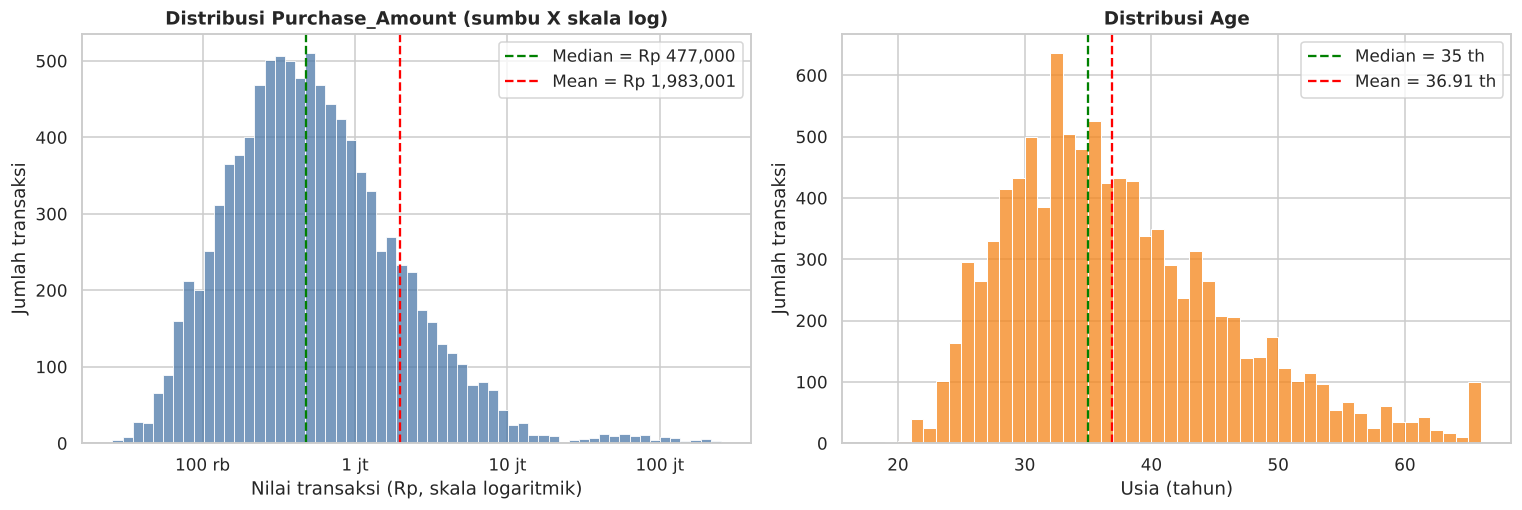

In [4]:
dist = pd.DataFrame({
    'Mean': df[['Purchase_Amount','Age']].mean(),
    'Median': df[['Purchase_Amount','Age']].median(),
    'Skewness': df[['Purchase_Amount','Age']].skew()})
dist['Mean / Median'] = dist.Mean / dist.Median
display(dist)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
# Purchase_Amount: skala log agar bentuk distribusi terlihat
sns.histplot(df.Purchase_Amount, bins=60, log_scale=True, color='#4c78a8', ax=ax[0])
ax[0].axvline(df.Purchase_Amount.median(), color='green', ls='--', label=f'Median = Rp {df.Purchase_Amount.median():,.0f}')
ax[0].axvline(df.Purchase_Amount.mean(), color='red', ls='--', label=f'Mean = Rp {df.Purchase_Amount.mean():,.0f}')
ax[0].xaxis.set_major_formatter(FuncFormatter(rp))
ax[0].set_title('Distribusi Purchase_Amount (sumbu X skala log)', fontweight='bold')
ax[0].set_xlabel('Nilai transaksi (Rp, skala logaritmik)'); ax[0].set_ylabel('Jumlah transaksi'); ax[0].legend()

sns.histplot(df.Age, bins=range(18, 67), color='#f58518', ax=ax[1])
ax[1].axvline(df.Age.median(), color='green', ls='--', label=f'Median = {df.Age.median():.0f} th')
ax[1].axvline(df.Age.mean(), color='red', ls='--', label=f'Mean = {df.Age.mean():.2f} th')
ax[1].set_title('Distribusi Age', fontweight='bold')
ax[1].set_xlabel('Usia (tahun)'); ax[1].set_ylabel('Jumlah transaksi'); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi**

- **`Purchase_Amount`: miring positif (right-skewed) sangat ekstrem.** Mean (Rp 1.983.001) sekitar **4,2 kali** median (Rp 477.000) dan skewness **14,39** (jauh di atas +1). Sedikit transaksi bernilai puluhan hingga ratusan juta menarik mean ke kanan, sedangkan mayoritas transaksi berada di bawah Rp 1,2 juta (Q3).
- **`Age`: miring positif ringan-sedang.** Mean (36,91) hanya sedikit di atas median (35) dan skewness **0,84**. Ada ekor ke usia tua, tetapi mean dan median masih berdekatan sehingga keduanya cukup informatif.
- **Metrik yang paling tepat untuk belanja tipikal: MEDIAN.** Alasan: (1) mean tidak mewakili siapa pun, karena Rp 1,98 juta berada di atas sekitar 85% transaksi (lihat sel di bawah); (2) mean sangat sensitif terhadap transaksi ekstrem, sedangkan median tidak (lihat uji sensitivitas di B.3: median hanya berubah 2% saat transaksi mencurigakan dibuang, mean berubah 45%). Mean tetap dipakai untuk **total omzet** (karena total = mean × n), bukan untuk "belanja tipikal".

In [5]:
print(f'Persentase transaksi di bawah mean Purchase_Amount: {(df.Purchase_Amount < df.Purchase_Amount.mean()).mean()*100:.1f}%')

Persentase transaksi di bawah mean Purchase_Amount: 84.9%


## B.3 Deteksi dan Evaluasi Outlier (Metode IQR)
Batas bawah = Q1 − 1,5×IQR dan batas atas = Q3 + 1,5×IQR, dihitung pada data asli (10.000 transaksi).

In [6]:
def batas_iqr(s):
    q1, q3 = s.quantile(.25), s.quantile(.75); iqr = q3 - q1
    return q1, q3, iqr, q1 - 1.5*iqr, q3 + 1.5*iqr

baris = []
for k in ['Purchase_Amount', 'Quantity']:
    q1, q3, iqr, lo, hi = batas_iqr(df[k])
    n_lo, n_hi = (df[k] < lo).sum(), (df[k] > hi).sum()
    baris.append({'Variabel': k, 'Q1': q1, 'Q3': q3, 'IQR': iqr, 'Batas Bawah': lo, 'Batas Atas': hi,
                  'Outlier Bawah': n_lo, 'Outlier Atas': n_hi, 'Total Outlier': n_lo+n_hi,
                  'Persentase (%)': (n_lo+n_hi)/len(df)*100})
tabel_iqr = pd.DataFrame(baris); display(tabel_iqr)

LO_A, HI_A = batas_iqr(df.Purchase_Amount)[3:]
LO_Q, HI_Q = batas_iqr(df.Quantity)[3:]
df['out_amt'] = (df.Purchase_Amount < LO_A) | (df.Purchase_Amount > HI_A)
df['out_qty'] = (df.Quantity < LO_Q) | (df.Quantity > HI_Q)
print('Outlier gabungan (salah satu):', (df.out_amt | df.out_qty).sum(), '| keduanya:', (df.out_amt & df.out_qty).sum())

tot = df.Purchase_Amount.sum()
print(f'Outlier Purchase_Amount = {df.out_amt.mean()*100:.2f}% transaksi, tetapi menyumbang {df.loc[df.out_amt,"Purchase_Amount"].sum()/tot*100:.1f}% total omzet')

,Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Outlier Bawah,Outlier Atas,Total Outlier,Persentase (%)
0,Purchase_Amount,"218,875.00","1,158,250.00","939,375.00","-1,190,187.50","2,567,312.50",0,1126,1126,11.26
1,Quantity,1.00,4.00,3.00,-3.50,8.50,0,386,386,3.86


Outlier gabungan (salah satu): 1313 | keduanya: 199
Outlier Purchase_Amount = 11.26% transaksi, tetapi menyumbang 72.9% total omzet


Batas bawah kedua variabel negatif, sedangkan nilai minimum `Purchase_Amount` adalah Rp 25.650 dan `Quantity` minimum 1, sehingga **tidak ada outlier bawah**; seluruh outlier berada di sisi atas.

### B.3.1 Karakteristik outlier: produk, kuantitas, dan tier membership

In [7]:
out = df[df.out_amt | df.out_qty].copy()

# a) Produk / kategori: jumlah outlier DAN proporsi terhadap seluruh transaksi kategori itu
kat = df.groupby('Product_Category').agg(Total_Trx=('Transaction_ID','size'),
                                        Outlier_Amount=('out_amt','sum'), Outlier_Qty=('out_qty','sum'))
kat['% Outlier Amount'] = kat.Outlier_Amount / kat.Total_Trx * 100
kat['% Outlier Qty'] = kat.Outlier_Qty / kat.Total_Trx * 100
display(kat.sort_values('Outlier_Amount', ascending=False))

# b) Produk spesifik pada outlier Purchase_Amount
display(df[df.out_amt].Product_Name.value_counts().head(8).rename('Jumlah outlier Amount').to_frame())

# c) Membership: bandingkan PROPORSI dalam tiap tier (bukan hanya jumlah)
urut = ['Basic','Silver','Gold','Premium']
mem = df.groupby('Membership_Level').agg(Total_Trx=('Transaction_ID','size'),
        Outlier_Amount=('out_amt','sum'), Outlier_Qty=('out_qty','sum'),
        Median_Amount=('Purchase_Amount','median')).reindex(urut)
mem['% Outlier Amount'] = mem.Outlier_Amount / mem.Total_Trx * 100
mem['% Outlier Qty'] = mem.Outlier_Qty / mem.Total_Trx * 100
display(mem)

,Total_Trx,Outlier_Amount,Outlier_Qty,% Outlier Amount,% Outlier Qty
Product_Category,,,,,
Electronics,1856,888,71,47.84,3.83
Home & Living,1986,132,82,6.65,4.13
Fashion,2204,73,90,3.31,4.08
Beauty & Health,1992,17,68,0.85,3.41
Groceries,1962,16,75,0.82,3.82


,Jumlah outlier Amount
Product_Name,
Smartwatch Pro,170
Noise Cancelling Headphones,165
27-Inch Monitor,165
Bluetooth Speaker,144
Wireless Earbuds,130
Mechanical Keyboard,114
Air Purifier Mini,32
Ergonomic Desk Lamp,29


,Total_Trx,Outlier_Amount,Outlier_Qty,Median_Amount,% Outlier Amount,% Outlier Qty
Membership_Level,,,,,,
Basic,4230,386,156,"440,650.00",9.13,3.69
Silver,2763,278,112,"410,400.00",10.06,4.05
Gold,1997,267,71,"533,000.00",13.37,3.56
Premium,1010,195,47,"806,300.00",19.31,4.65


**Temuan:**
- **Produk:** 888 dari 1.126 outlier `Purchase_Amount` (78,9%) adalah **Electronics**, dan 47,8% dari seluruh transaksi Electronics masuk kategori outlier. Artinya Electronics memang berharga tinggi, sehingga sebagian besar "outlier" adalah transaksi normal untuk kategori mahal, bukan anomali.
- **Membership:** Dengan **jumlah**, Basic tampak paling banyak (karena Basic memang 42% dari seluruh transaksi). Dengan **proporsi**, justru **Premium paling sering outlier (19,3%)**, lalu Gold (13,4%), Silver (10,1%), Basic (9,1%). Jadi pola ini konsisten dengan hipotesis bahwa tier tinggi belanja lebih besar. Sebaliknya, outlier **Quantity** sebanding di semua tier (3,6% s.d. 4,7%), sehingga kuantitas ekstrem tidak dipengaruhi tier.
- Memakai rata-rata outlier per tier (seperti versi sebelumnya) menyesatkan, karena nilainya dikuasai beberapa baris ratusan juta.

### B.3.2 Memeriksa apakah outlier ini wajar: dua pola yang mencurigakan
IQR hanya menunjukkan nilai yang jauh dari pusat, bukan apakah nilai itu **salah**. Dua pemeriksaan lanjutan:

1. **Quantity:** sebaran `Quantity` memiliki celah (gap) yang tegas: ada nilai 1 s.d. 10, kemudian **tidak ada satu pun transaksi dengan Quantity 11 s.d. 14**, lalu muncul 94 transaksi dengan Quantity 15 s.d. 55. Batas IQR (8,5) sendiri memotong di tengah ekor yang wajar (Quantity 9 dan 10 ikut ditandai padahal masih bagian dari pola normal).
2. **Unit_Price:** harga satuan satu produk seharusnya stabil, tetapi beberapa produk bervariasi tidak masuk akal (misalnya *Organic Honey Jar* dan *Arabica Coffee Beans 500g* tercatat dengan harga jutaan rupiah per unit, padahal median produk itu sekitar Rp 90.000).

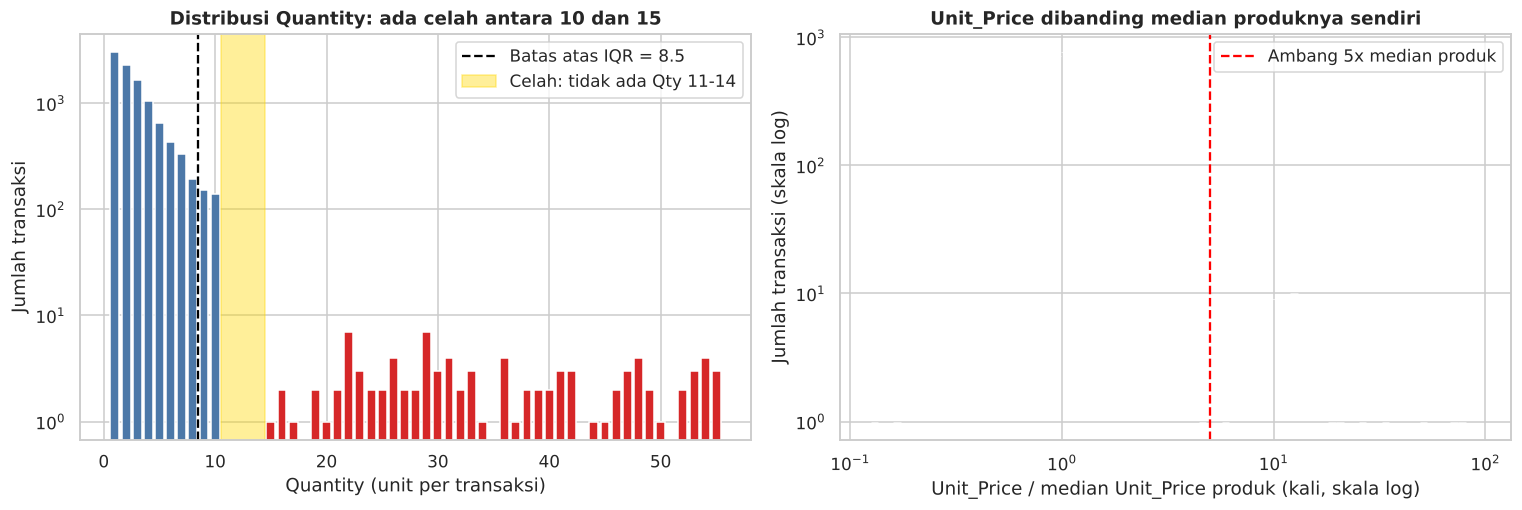

Quantity > 10 : 94 baris | rata-rata Qty = 34.9 (vs median Qty normal = 2)
Harga > 5x median produk: 89 baris
Irisan keduanya: 28 | gabungan baris mencurigakan: 155

Sebaran Quantity>10 per kategori: {'Home & Living': 25, 'Groceries': 20, 'Electronics': 19, 'Beauty & Health': 17, 'Fashion': 13}
Sebaran Harga ekstrem per kategori: {'Electronics': 63, 'Home & Living': 8, 'Fashion': 8, 'Groceries': 7, 'Beauty & Health': 3}
Sensitivitas ambang harga (jumlah baris): 4x = 102 | 5x = 89 | 6x = 83


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
vc = df.Quantity.value_counts().reindex(range(1, 56), fill_value=0)
ax[0].bar(vc.index, vc.values, color=['#4c78a8' if q <= 10 else '#d62728' for q in vc.index])
ax[0].axvline(HI_Q, color='black', ls='--', label=f'Batas atas IQR = {HI_Q}')
ax[0].axvspan(10.5, 14.5, color='gold', alpha=.4, label='Celah: tidak ada Qty 11-14')
ax[0].set_title('Distribusi Quantity: ada celah antara 10 dan 15', fontweight='bold')
ax[0].set_xlabel('Quantity (unit per transaksi)'); ax[0].set_ylabel('Jumlah transaksi'); ax[0].set_yscale('log'); ax[0].legend()

df['Median_Harga_Produk'] = df.groupby('Product_Name').Unit_Price.transform('median')
df['Rasio_Harga'] = df.Unit_Price / df.Median_Harga_Produk
sns.histplot(df.Rasio_Harga, bins=80, log_scale=(True, True), color='#4c78a8', ax=ax[1])
ax[1].axvline(5, color='red', ls='--', label='Ambang 5x median produk')
ax[1].set_title('Unit_Price dibanding median produknya sendiri', fontweight='bold')
ax[1].set_xlabel('Unit_Price / median Unit_Price produk (kali, skala log)'); ax[1].set_ylabel('Jumlah transaksi (skala log)'); ax[1].legend()
plt.tight_layout(); plt.show()

df['qty_ekstrem'] = df.Quantity > 10
df['harga_ekstrem'] = df.Rasio_Harga > 5
print('Quantity > 10 :', df.qty_ekstrem.sum(), 'baris | rata-rata Qty =', round(df.loc[df.qty_ekstrem,'Quantity'].mean(),1), '(vs median Qty normal = 2)')
print('Harga > 5x median produk:', df.harga_ekstrem.sum(), 'baris')
print('Irisan keduanya:', (df.qty_ekstrem & df.harga_ekstrem).sum(), '| gabungan baris mencurigakan:', (df.qty_ekstrem | df.harga_ekstrem).sum())
print()
print('Sebaran Quantity>10 per kategori:', df[df.qty_ekstrem].Product_Category.value_counts().to_dict())
print('Sebaran Harga ekstrem per kategori:', df[df.harga_ekstrem].Product_Category.value_counts().to_dict())
print('Sensitivitas ambang harga (jumlah baris): 4x =', (df.Rasio_Harga>4).sum(), '| 5x =', (df.Rasio_Harga>5).sum(), '| 6x =', (df.Rasio_Harga>6).sum())

**Catatan jujur tentang ambang 5x:** angka ini adalah heuristik, bukan aturan baku. Pada grafik, rasio harga wajar menyebar hingga sekitar 4x median, lalu ada ekor jarang hingga 95x. Uji sensitivitas menunjukkan hasilnya stabil (102 / 89 / 83 baris pada ambang 4x / 5x / 6x). Dataset **tidak bisa membuktikan** apakah baris-baris ini salah input atau memang pembelian khusus. Karena itu baris ini diberi status **"perlu diverifikasi"**, bukan langsung dihapus.

,Jumlah,Total_Omzet,Median_Amount,% dari 10.000 trx,% dari total omzet
Segmen,,,,,
A. Wajar (produk mahal / multi-unit normal),1159,"5,572,919,450.00","3,839,400.00",11.59,28.10
B. Quantity ekstrem (>10),66,"1,317,543,050.00","7,195,500.00",0.66,6.64
C. Qty>10 DAN harga ekstrem,28,"4,437,329,400.00","143,811,950.00",0.28,22.38
D. Harga satuan ekstrem (>5x median produk),60,"3,367,832,900.00","52,950,625.00",0.60,16.98


Baris mencurigakan (B+C+D) di luar outlier IQR: 1


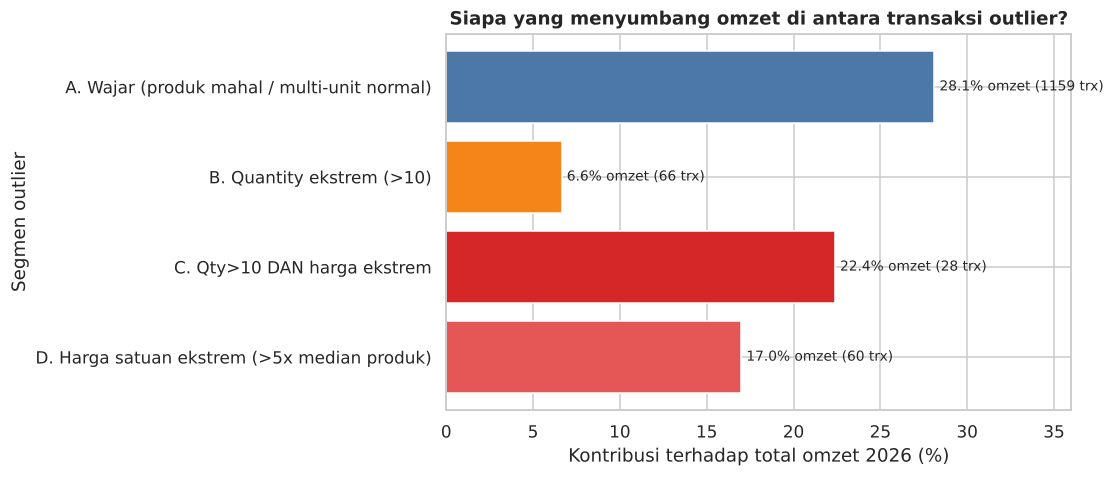

In [9]:
# Segmentasi outlier IQR menjadi 4 jenis
def segmen(r):
    if r.qty_ekstrem and r.harga_ekstrem: return 'C. Qty>10 DAN harga ekstrem'
    if r.qty_ekstrem:  return 'B. Quantity ekstrem (>10)'
    if r.harga_ekstrem: return 'D. Harga satuan ekstrem (>5x median produk)'
    return 'A. Wajar (produk mahal / multi-unit normal)'

o = df[df.out_amt | df.out_qty].copy()
o['Segmen'] = o.apply(segmen, axis=1)
seg = o.groupby('Segmen').agg(Jumlah=('Transaction_ID','size'),
                              Total_Omzet=('Purchase_Amount','sum'),
                              Median_Amount=('Purchase_Amount','median'))
seg['% dari 10.000 trx'] = seg.Jumlah / len(df) * 100
seg['% dari total omzet'] = seg.Total_Omzet / df.Purchase_Amount.sum() * 100
display(seg)
print('Baris mencurigakan (B+C+D) di luar outlier IQR:', (df.qty_ekstrem | df.harga_ekstrem).sum() - (o.Segmen != 'A. Wajar (produk mahal / multi-unit normal)').sum())

fig, ax = plt.subplots(figsize=(10, 4.5))
s = seg.sort_index()
ax.barh(s.index, s['% dari total omzet'], color=['#4c78a8','#f58518','#d62728','#e45756'])
for i, (v, n) in enumerate(zip(s['% dari total omzet'], s.Jumlah)):
    ax.text(v + .3, i, f'{v:.1f}% omzet ({n} trx)', va='center', fontsize=9)
ax.set_xlim(0, 36); ax.invert_yaxis()
ax.set_title('Siapa yang menyumbang omzet di antara transaksi outlier?', fontweight='bold')
ax.set_xlabel('Kontribusi terhadap total omzet 2026 (%)'); ax.set_ylabel('Segmen outlier')
plt.tight_layout(); plt.show()

**Temuan penting:** dari 1.313 transaksi outlier IQR, **1.159 (88%) tergolong wajar** (produk elektronik mahal atau beli beberapa unit), sedangkan **154 transaksi (1,5% dari seluruh data) mencurigakan**. Ironisnya, transaksi mencurigakan inilah yang paling besar nilainya: hanya sekitar 1,5% baris, tetapi menyumbang sekitar **46% total omzet**. Satu transaksi bernilai Rp 251 juta (Air Purifier Mini, Qty 31, harga Rp 9 juta per unit padahal median produknya Rp 323 ribu) saja setara dengan omzet sekitar 500 transaksi bertipikal (median Rp 477 ribu).

### B.3.3 Uji sensitivitas: seberapa besar baris mencurigakan memengaruhi statistik?

In [10]:
mencurigakan = df.qty_ekstrem | df.harga_ekstrem
versi = {'Semua data (10.000)': df, 'Tanpa baris mencurigakan': df[~mencurigakan]}
rows = []
for nama, d in versi.items():
    rows.append({'Versi': nama, 'n': len(d), 'Mean': d.Purchase_Amount.mean(), 'Median': d.Purchase_Amount.median(),
                 'Std Dev': d.Purchase_Amount.std(), 'Skewness': d.Purchase_Amount.skew(),
                 'Total omzet (Rp miliar)': d.Purchase_Amount.sum()/1e9})
sens = pd.DataFrame(rows).set_index('Versi'); display(sens)
print(f'Perubahan MEAN  : {(sens.Mean.iloc[1]/sens.Mean.iloc[0]-1)*100:.1f}%')
print(f'Perubahan MEDIAN: {(sens.Median.iloc[1]/sens.Median.iloc[0]-1)*100:.1f}%')

# Konsistensi dengan data bersih Bagian A (IQR dihitung ulang pada data tsb)
q = batas_iqr(df_bersih.Purchase_Amount); qq = batas_iqr(df_bersih.Quantity)
print('\nData bersih (9.557): outlier Purchase_Amount =', ((df_bersih.Purchase_Amount>q[4])).sum(),
      f'({(df_bersih.Purchase_Amount>q[4]).mean()*100:.2f}%) | outlier Quantity =', (df_bersih.Quantity>qq[4]).sum(),
      f'({(df_bersih.Quantity>qq[4]).mean()*100:.2f}%)')

,n,Mean,Median,Std Dev,Skewness,Total omzet (Rp miliar)
Versi,,,,,,
Semua data (10.000),10000,"1,983,001.00","477,000.00","10,323,960.75",14.39,19.83
Tanpa baris mencurigakan,9845,"1,087,431.97","467,400.00","1,903,849.40",5.37,10.71


Perubahan MEAN  : -45.2%
Perubahan MEDIAN: -2.0%

Data bersih (9.557): outlier Purchase_Amount = 1084 (11.34%) | outlier Quantity = 367 (3.84%)


### B.3.4 Rekomendasi analitis: hapus atau pertahankan?

**Rekomendasi: JANGAN hapus semua outlier. Gunakan pendekatan tiga tingkat.**

| Segmen | Jumlah | Keputusan | Alasan bisnis |
|---|---:|---|---|
| **A. Wajar** (elektronik mahal / multi-unit) | 1.159 | **Pertahankan** | Ini adalah pelanggan bernilai tinggi dan inti omzet Electronics (55,8% omzet). Menghapusnya membuat laporan meremehkan pendapatan dan salah menilai segmen premium. |
| **B/C/D. Mencurigakan** (Qty > 10 dan/atau harga > 5x median produk) | 154 | **Pertahankan di total omzet, tandai (flag) dan verifikasi ke tim sumber data**; **sajikan metrik "tipikal" tanpa baris ini** | Tidak terbukti salah, tetapi tidak masuk akal secara bisnis (madu Rp 8,5 juta per toples). Jika ternyata salah input, omzet terlalu tinggi ~46%. Jika ternyata pesanan korporat/grosir, menghapusnya membuang pelanggan B2B. Karena belum bisa dipastikan, manajemen perlu melihat kedua angka. |
| **Pelaporan** | - | **Pakai median untuk "belanja tipikal", pakai total + catatan untuk omzet** | Median stabil (berubah 2%) sedangkan mean berubah 45% saat baris mencurigakan dikeluarkan. |

Tindak lanjut yang disarankan: (1) audit proses input harga dan kuantitas, (2) validasi harga per SKU (misalnya batas ±5x harga katalog), (3) pisahkan kanal grosir/B2B bila Qty besar memang sah.